In [6]:
import transformer
import torch
import torch.nn as nn
import torch.optim as optim
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
import time
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import pipeline
import numpy as np
from sklearn.decomposition import PCA

#Downloading IMDB dataset from keras.datasets

In [2]:

# 1. TELL PYTORCH TO USE THE GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Hardware engine connected: {device.type.upper()}\n")

print("1. Downloading 10,000 real IMDB movie reviews...")
vocab_size = 10000
(X_train_full, y_train_full), (X_test_full, y_test_full)= imdb.load_data(num_words=vocab_size)#  is list of lists

print("2. Preparing the data...")
# We can now handle 10,000 reviews easily because GPUs process matrices in parallel
X_train_slice = X_train_full
y_train_slice = y_train_full

max_length = 100 # Increased sentence length to 100 words
X_train_padded = pad_sequences(X_train_slice, maxlen=max_length, padding='post') #chopped the ends off long reviews and added zeros to short ones. This forced the jagged list into a perfect 2D rectangle

X_train = torch.tensor(X_train_padded, dtype=torch.long)
y_train = torch.tensor(y_train_slice, dtype=torch.long)

Hardware engine connected: CUDA

1. Downloading 10,000 real IMDB movie reviews...
2. Preparing the data...


/tmp/ipykernel_291520/4153516590.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train_full, palette=['crimson', 'mediumseagreen'])


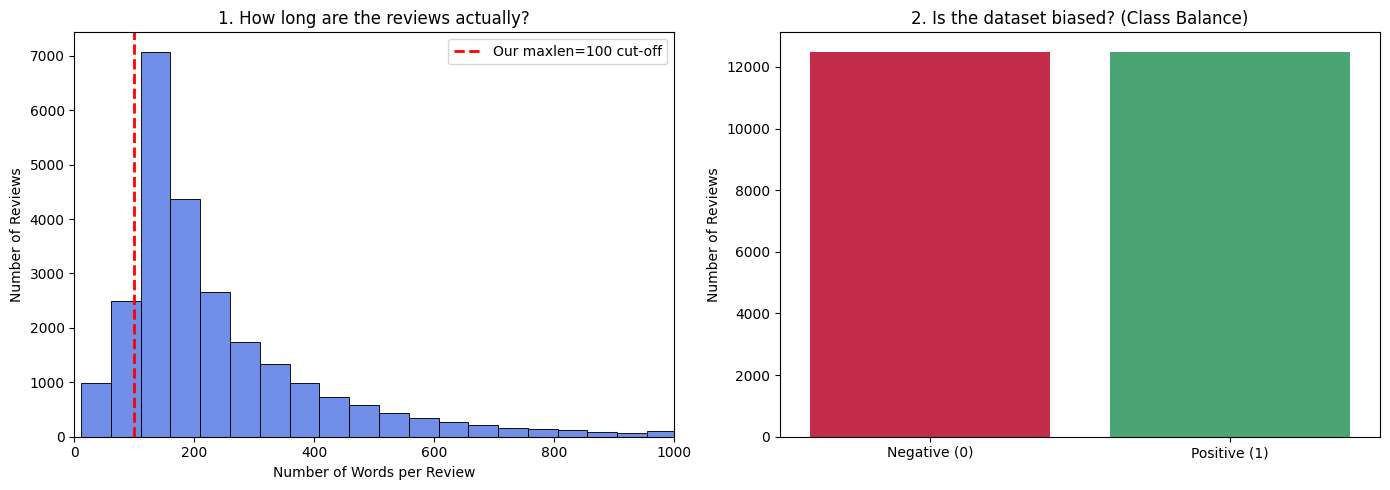

In [3]:

# Calculate the actual word count of every single review in the dataset
review_lengths = [len(review) for review in X_train_full]

plt.figure(figsize=(14, 5))

# ==========================================
# PLOT 1: REVIEW LENGTH DISTRIBUTION
# ==========================================
plt.subplot(1, 2, 1)
sns.histplot(review_lengths, bins=50, color='royalblue')
# We draw a red line right where we cut the data off with maxlen=100
plt.axvline(x=100, color='red', linestyle='--', linewidth=2, label='Our maxlen=100 cut-off')
plt.title("1. How long are the reviews actually?")
plt.xlabel("Number of Words per Review")
plt.ylabel("Number of Reviews")
plt.xlim(0, 1000)
plt.legend()

# ==========================================
# PLOT 2: POSITIVE VS NEGATIVE BALANCE
# ==========================================
plt.subplot(1, 2, 2)
sns.countplot(x=y_train_full, palette=['crimson', 'mediumseagreen'])
plt.title("2. Is the dataset biased? (Class Balance)")
plt.xticks(ticks=[0, 1], labels=["Negative (0)", "Positive (1)"])
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

# Training:
##### We will use a small transformer

In [4]:
print("3. Initializing Transformer and moving it to GPU...")
# We make the engine slightly bigger for better learning
model = transformer.TransformerClassifier(vocab_size=vocab_size, d_model=64, num_heads=8, d_ff=256, num_layers=2)
model = model.to(device) # <--- THIS PUSHES THE NEURAL NETWORK TO THE GPU
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

print("\n--- TRAINING ON GPU ---")
epochs = 100
batch_size = 100 # Processing 100 sentences simultaneously

start_time = time.time()

for epoch in range(epochs):
    total_loss = 0
    # Process 10,000 reviews in chunks of 100
    for i in range(0, len(X_train_slice), batch_size):
        # Grab a batch and push the data to the GPU
        batch_X = X_train[i:i+batch_size].to(device)#shape:
        batch_y = y_train[i:i+batch_size].to(device)
        # Safety catch: if a batch is empty (just in case), skip it
        if len(batch_X) == 0:
            continue
        optimizer.zero_grad()
        predictions = model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/5 | Average Loss: {total_loss / (10000/batch_size):.4f}")

end_time = time.time()
print(f"\nTraining Complete! 10,000 reviews processed in {end_time - start_time:.1f} seconds.")

3. Initializing Transformer and moving it to GPU...

--- TRAINING ON GPU ---
Epoch 1/5 | Average Loss: 1.4375
Epoch 2/5 | Average Loss: 1.1075
Epoch 3/5 | Average Loss: 1.0047
Epoch 4/5 | Average Loss: 0.9494
Epoch 5/5 | Average Loss: 0.8920
Epoch 6/5 | Average Loss: 0.8536
Epoch 7/5 | Average Loss: 0.8295
Epoch 8/5 | Average Loss: 0.7877
Epoch 9/5 | Average Loss: 0.7609
Epoch 10/5 | Average Loss: 0.7380
Epoch 11/5 | Average Loss: 0.7139
Epoch 12/5 | Average Loss: 0.6982
Epoch 13/5 | Average Loss: 0.6674
Epoch 14/5 | Average Loss: 0.6555
Epoch 15/5 | Average Loss: 0.6353
Epoch 16/5 | Average Loss: 0.6215
Epoch 17/5 | Average Loss: 0.6078
Epoch 18/5 | Average Loss: 0.5946
Epoch 19/5 | Average Loss: 0.5797
Epoch 20/5 | Average Loss: 0.5695
Epoch 21/5 | Average Loss: 0.5540
Epoch 22/5 | Average Loss: 0.5351
Epoch 23/5 | Average Loss: 0.5191
Epoch 24/5 | Average Loss: 0.5154
Epoch 25/5 | Average Loss: 0.4880
Epoch 26/5 | Average Loss: 0.4821
Epoch 27/5 | Average Loss: 0.4829
Epoch 28/5 | A

# Test evaluation on IMDB dataset review

In [7]:
# Setup device (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Downloading Pre-trained Sentiment Transformer...")
hf_device = 0 if torch.cuda.is_available() else -1
sentiment_model = pipeline("sentiment-analysis", truncation=True, device=hf_device)

print("Loading IMDB Test data...")
# Grab the exact same 500 reviews for both models to test on
sample_size = 500
x_sample = X_test_full[:sample_size]
y_sample = y_test_full[:sample_size]

# ==========================================
# 1. TEST PRE-TRAINED HUGGING FACE MODEL
# ==========================================
print(f"\nTesting {sample_size} reviews through Pre-Trained Transformer...")
word_index = imdb.get_word_index()
reverse_word_index = {value: key for (key, value) in word_index.items()}

def decode_review(encoded_review):
    return ' '.join([reverse_word_index.get(i - 3, '') for i in encoded_review]).strip()

hf_correct = 0
for i in range(sample_size):
    english_review = decode_review(x_sample[i])
    result = sentiment_model(english_review)[0]
    prediction = 1 if result['label'] == 'POSITIVE' else 0
    if prediction == y_sample[i]:
        hf_correct += 1

hf_accuracy = (hf_correct / sample_size) * 100

# ==========================================
# 2. TEST YOUR CUSTOM SMALL TRANSFORMER
# ==========================================
print(f"Testing {sample_size} reviews through your Custom Transformer...")
# Pad to 100 to match your model's training architecture
x_padded = pad_sequences(x_sample, maxlen=100, padding='post', truncating='post')

test_inputs = torch.tensor(x_padded, dtype=torch.long).to(device)
test_labels = torch.tensor(y_sample, dtype=torch.long).to(device)

model.to(device)
model.eval()
with torch.no_grad():
    # Pass all 500 reviews through your model in one batch
    logits = model(test_inputs)
    custom_predictions = torch.argmax(logits, dim=1)
    custom_correct = (custom_predictions == test_labels).sum().item()

custom_accuracy = (custom_correct / sample_size) * 100

# ==========================================
# 3. PRINT SIDE-BY-SIDE RESULTS
# ==========================================
print("\n" + "="*50)
print(f"RESULTS ON {sample_size} IMDB TEST REVIEWS")
print("="*50)
print(f"Pre-Trained Transformer Accuracy:   {hf_accuracy:.1f}%")
print(f"Small Custom Model Accuracy:        {custom_accuracy:.1f}%")
print("="*50)

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading IMDB Test data...

Testing 500 reviews through Pre-Trained Transformer...


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Testing 500 reviews through your Custom Transformer...

RESULTS ON 500 IMDB TEST REVIEWS
Pre-Trained Transformer Accuracy:   88.4%
Small Custom Model Accuracy:        77.2%
